# ⭐ Atrapa la estrella: solución explicada paso a paso
**Actividad de iniciación · Programación (0485) · 1.º DAW**

En este cuaderno resolvemos, fase a fase, la actividad **Atrapa la estrella**: una cesta que se mueve con las flechas tiene que recoger las estrellas que caen. En cada fase verás:

1. 🎯 **Qué** hay que conseguir.
2. 🧠 **Cómo** pensarlo.
3. 💻 **El código** de la solución, explicado.
4. 🔬 **Una prueba** que puedes ejecutar.

> ⚠️ **Importante.** Pygame Zero abre una **ventana**, y Google Colab no tiene pantalla. Por eso aquí **simulamos** la pantalla y el teclado: las funciones del juego son *las mismas* que en `estrella.py`, pero los dibujos aparecen como imágenes dentro del cuaderno. Al final puedes descargar `estrella.py` para jugar en tu ordenador.

Ejecuta las celdas **en orden** (`Mayús + Intro`), o usa *Entorno de ejecución → Ejecutar todas*.

## 0. Preparación: un "Pygame Zero de mentira"
Pygame Zero nos da ya creados `screen`, `keyboard`, `keys` y `Rect`. En Colab no existen, así que la siguiente celda crea **imitaciones** que se usan igual. No hace falta entenderla por dentro: basta con ejecutarla.

In [1]:
# Instala pygame si no está disponible (en Colab tarda unos segundos)
try:
    import pygame
except ImportError:
    !pip install -q pygame
    import pygame

pygame 2.6.1 (SDL 2.28.4, Python 3.10.12)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [2]:
import os, io, random
os.environ["SDL_VIDEODRIVER"] = "dummy"   # sin ventana
os.environ["SDL_AUDIODRIVER"] = "dummy"   # sin sonido
import pygame
from pygame import Rect                   # el mismo Rect que usa Pygame Zero
from types import SimpleNamespace
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Image as IPyImage, display
pygame.init()


class _Dibujo:
    """Imita screen.draw de Pygame Zero."""
    def __init__(self, superficie):
        self.superficie = superficie

    def filled_rect(self, rect, color):
        pygame.draw.rect(self.superficie, color, rect)

    def filled_circle(self, pos, radio, color):
        pygame.draw.circle(self.superficie, color, (int(pos[0]), int(pos[1])), radio)

    def text(self, texto, center=None, topleft=None, fontsize=24, color="white"):
        fuente = pygame.font.Font(None, fontsize)
        imagen = fuente.render(texto, True, pygame.Color(color) if isinstance(color, str) else color)
        if topleft is not None:
            caja = imagen.get_rect(topleft=(int(topleft[0]), int(topleft[1])))
        else:
            caja = imagen.get_rect(center=(int(center[0]), int(center[1])))
        self.superficie.blit(imagen, caja)


class PantallaSimulada:
    """Imita el objeto screen de Pygame Zero, pero dibuja en memoria."""
    def __init__(self, ancho, alto):
        self.surface = pygame.Surface((ancho, alto))
        self.draw = _Dibujo(self.surface)

    def fill(self, color):
        self.surface.fill(color)

    def imagen(self):
        datos = pygame.image.tobytes(self.surface, "RGB")
        return Image.frombytes("RGB", self.surface.get_size(), datos)


def mostrar(*imagenes, titulos=None):
    """Muestra una o varias capturas de pantalla una al lado de otra."""
    fig, ejes = plt.subplots(1, len(imagenes), figsize=(6 * len(imagenes), 3.8))
    if len(imagenes) == 1:
        ejes = [ejes]
    for i, (eje, img) in enumerate(zip(ejes, imagenes)):
        eje.imshow(img)
        eje.axis("off")
        if titulos:
            eje.set_title(titulos[i])
    plt.tight_layout()
    plt.show()


# El teclado: cada tecla vale True mientras está "pulsada"
keyboard = SimpleNamespace(left=False, right=False)
# Códigos de teclas para on_key_down
keys = SimpleNamespace(SPACE="SPACE")

print("Simulador de Pygame Zero listo ✔")

Simulador de Pygame Zero listo ✔


---
## Fase 1 · Puntos y vidas en pantalla

🎯 **Objetivo:** mostrar `Puntos: 0` arriba a la izquierda y **un círculo rosa por cada vida** arriba a la derecha.

### 🧠 Cómo pensarlo
- Los números con significado se guardan en **constantes** (en MAYÚSCULAS). Si queremos una cesta más ancha, cambiamos una sola línea.
- `screen.draw.text()` escribe **texto**. Para unir texto y número hay que convertir el número: `"Puntos: " + str(puntos)`.
- Para dibujar 3 vidas no escribimos 3 líneas: usamos `for i in range(vidas)`. En cada vuelta `i` vale 0, 1, 2…, y la usamos para separar los círculos 30 píxeles.

In [3]:
WIDTH = 600
HEIGHT = 480

COLOR_FONDO = (12, 10, 40)
COLOR_CESTA = (0, 220, 255)
COLOR_ESTRELLA = (255, 230, 90)
COLOR_VIDA = (255, 60, 170)
COLOR_TEXTO = (255, 255, 255)

CESTA_ANCHO = 90
CESTA_ALTO = 18
CESTA_VELOCIDAD = 8
RADIO = 12
VELOCIDAD_INICIAL = 3
AUMENTO_VELOCIDAD = 0.3
VIDAS_INICIALES = 3

# Solo en el simulador: en Pygame Zero 'screen' ya existe
screen = PantallaSimulada(WIDTH, HEIGHT)

# Estado del juego
cesta = Rect(WIDTH // 2 - CESTA_ANCHO // 2, HEIGHT - 40, CESTA_ANCHO, CESTA_ALTO)
estrella_x = WIDTH / 2
estrella_y = 100
velocidad = VELOCIDAD_INICIAL
puntos = 0
vidas = VIDAS_INICIALES
estado = "jugando"

print("La cesta es un Rect:", cesta)

La cesta es un Rect: <rect(255, 440, 90, 18)>


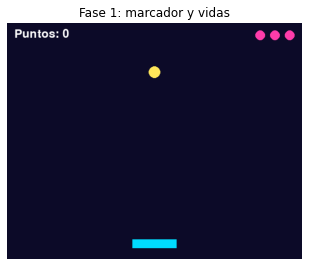

vida 0: círculo en x = 575
vida 1: círculo en x = 545
vida 2: círculo en x = 515


In [4]:
def dibujar_marcador():
    screen.draw.text("Puntos: " + str(puntos), topleft=(15, 10),
                     fontsize=36, color=COLOR_TEXTO)
    for i in range(vidas):
        screen.draw.filled_circle((WIDTH - 25 - i * 30, 25), 10, COLOR_VIDA)


def draw():                              # versión FASE 1
    screen.fill(COLOR_FONDO)
    screen.draw.filled_circle((estrella_x, estrella_y), RADIO, COLOR_ESTRELLA)
    screen.draw.filled_rect(cesta, COLOR_CESTA)
    dibujar_marcador()


draw()
mostrar(screen.imagen(), titulos=["Fase 1: marcador y vidas"])
for i in range(vidas):
    print(f"vida {i}: círculo en x = {WIDTH - 25 - i * 30}")

> 💡 **Prueba tú:** cambia `vidas = 5` en una celda nueva, ejecuta `draw()` y `mostrar(screen.imagen())`. ¡Saldrán 5 círculos sin tocar `dibujar_marcador()`!

---
## Fase 2 · Mover la cesta

🎯 **Objetivo:** mover la cesta con ← y → sin que se salga de la pantalla.

### 🧠 Cómo pensarlo
- `keyboard.left` vale `True` **mientras** la flecha izquierda está pulsada. Como `update()` se ejecuta 60 veces por segundo, cada vez que se ejecute con la flecha pulsada movemos la cesta `CESTA_VELOCIDAD` píxeles.
- Izquierda = **restar** a la `x`; derecha = **sumar**.
- Un `Rect` conoce sus bordes: `cesta.left` y `cesta.right`. Si un borde se sale, lo colocamos justo en el límite.

> 🤔 **¿Por qué no hace falta `global cesta`?** Porque no creamos una cesta nueva: solo cambiamos un **atributo** (`cesta.x`) del objeto que ya existe.

In [5]:
def mover_cesta():
    if keyboard.left:
        cesta.x -= CESTA_VELOCIDAD
    if keyboard.right:
        cesta.x += CESTA_VELOCIDAD

    if cesta.left < 0:
        cesta.left = 0
    if cesta.right > WIDTH:
        cesta.right = WIDTH

### 🔬 Prueba: mantenemos pulsada cada flecha durante 100 fotogramas

Tras pulsar ← : cesta.left = 0
Tras pulsar → : cesta.right = 600 (WIDTH = 600 )


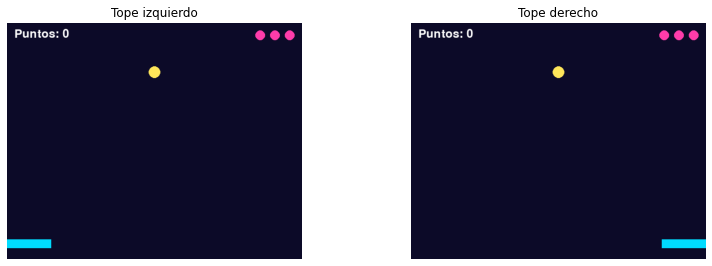

In [6]:
keyboard.left = True
for fotograma in range(100):
    mover_cesta()
keyboard.left = False
draw(); captura_izq = screen.imagen()
print("Tras pulsar ← : cesta.left =", cesta.left)

keyboard.right = True
for fotograma in range(100):
    mover_cesta()
keyboard.right = False
draw(); captura_der = screen.imagen()
print("Tras pulsar → : cesta.right =", cesta.right, "(WIDTH =", WIDTH, ")")

mostrar(captura_izq, captura_der, titulos=["Tope izquierdo", "Tope derecho"])

---
## Fase 3 · La estrella cae

🎯 **Objetivo:** la estrella cae y, al llegar abajo, reaparece arriba en una `x` aleatoria.

### 🧠 Cómo pensarlo
- **Caer** = sumar `velocidad` a `estrella_y` en cada fotograma (la `y` crece hacia abajo).
- **Reaparecer** lo haremos varias veces (al escaparse, al atraparla, al reiniciar), así que lo metemos en una **función**: `nueva_estrella()`.
- `random.randint(RADIO, WIDTH - RADIO)` da una `x` al azar que deja la estrella **entera** dentro de la pantalla.
- La estrella ha salido cuando su punto más alto (`estrella_y - RADIO`) pasa de `HEIGHT`.

Estas funciones **asignan** valores a variables globales, así que necesitan `global`.

In [7]:
def nueva_estrella():
    """Coloca la estrella arriba del todo, en una x aleatoria."""
    global estrella_x, estrella_y
    estrella_x = random.randint(RADIO, WIDTH - RADIO)
    estrella_y = -RADIO


def mover_estrella():                    # versión FASE 3
    global estrella_y
    estrella_y += velocidad
    if estrella_y - RADIO > HEIGHT:
        nueva_estrella()


random.seed(1)
print("Cinco posiciones de salida al azar:")
for _ in range(5):
    nueva_estrella()
    print("  x =", estrella_x, "· y =", estrella_y)

Cinco posiciones de salida al azar:
  x = 149 · y = -12
  x = 76 · y = -12
  x = 273 · y = -12
  x = 132 · y = -12
  x = 519 · y = -12


### 🔬 Prueba: ¿cómo cambia `estrella_y` con el tiempo?

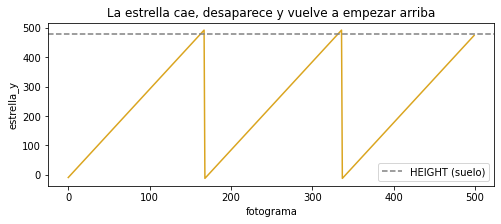

In [8]:
nueva_estrella()
alturas = []
for fotograma in range(500):
    mover_estrella()
    alturas.append(estrella_y)

plt.figure(figsize=(8, 3))
plt.plot(alturas, color="goldenrod")
plt.axhline(HEIGHT, ls="--", color="gray", label="HEIGHT (suelo)")
plt.xlabel("fotograma"); plt.ylabel("estrella_y"); plt.legend()
plt.title("La estrella cae, desaparece y vuelve a empezar arriba")
plt.show()

La gráfica es un **diente de sierra**: `y` crece en línea recta (caída a velocidad constante) y, al pasar de `HEIGHT`, vuelve de golpe a `-RADIO`.

---
## Fase 4 · ¡Atrapada!

🎯 **Objetivo:** si la estrella toca la cesta → +1 punto, más velocidad y estrella nueva.

### 🧠 Cómo pensarlo
- La estrella es un círculo, pero para el choque la tratamos como el **cuadrado que la rodea** (su *caja de colisión*). Así podemos usar `colliderect()`.
- Usamos `if ... elif ...` porque son **dos casos excluyentes**: o se atrapa, o se escapa. Con dos `if` separados, tras atraparla y lanzar una estrella nueva el programa haría otra comprobación que ya no tiene sentido en ese fotograma.

In [9]:
estrella_x, estrella_y = cesta.centerx, cesta.top - 5
caja = Rect(estrella_x - RADIO, estrella_y - RADIO, RADIO * 2, RADIO * 2)
print("Caja de la estrella:", caja, "· cesta:", cesta)
print("¿Se tocan?", caja.colliderect(cesta))

Caja de la estrella: <rect(543, 423, 24, 24)> · cesta: <rect(510, 440, 90, 18)>
¿Se tocan? True


In [10]:
def mover_estrella():                    # versión FASE 4
    global estrella_y, puntos, velocidad
    estrella_y += velocidad

    caja = Rect(estrella_x - RADIO, estrella_y - RADIO, RADIO * 2, RADIO * 2)
    if caja.colliderect(cesta):
        puntos += 1
        velocidad += AUMENTO_VELOCIDAD
        nueva_estrella()
    elif estrella_y - RADIO > HEIGHT:
        nueva_estrella()

### 🔬 Prueba: dejamos caer 5 estrellas justo encima de la cesta

In [11]:
puntos, velocidad = 0, VELOCIDAD_INICIAL
for n in range(5):
    estrella_x, estrella_y = cesta.centerx, 0      # la ponemos encima de la cesta
    fotogramas = 0
    puntos_antes = puntos
    while puntos == puntos_antes:
        mover_estrella()
        fotogramas += 1
    print(f"Estrella {n + 1}: atrapada en {fotogramas:>3} fotogramas · puntos = {puntos} · velocidad = {velocidad:.1f}")

Estrella 1: atrapada en 143 fotogramas · puntos = 1 · velocidad = 3.3
Estrella 2: atrapada en 130 fotogramas · puntos = 2 · velocidad = 3.6
Estrella 3: atrapada en 120 fotogramas · puntos = 3 · velocidad = 3.9
Estrella 4: atrapada en 111 fotogramas · puntos = 4 · velocidad = 4.2
Estrella 5: atrapada en 103 fotogramas · puntos = 5 · velocidad = 4.5


✔ Cada estrella llega antes que la anterior: la velocidad sube 0,3 píxeles por fotograma en cada captura.

---
## Fase 5 · Vidas y fin de partida

🎯 **Objetivo:** perder una vida por cada estrella que se escapa. Con 0 vidas aparece la pantalla final, y con ESPACIO se vuelve a jugar.

### 🧠 Cómo pensarlo: una **variable de estado**
```
 "jugando" ──vidas llega a 0──▶ "fin"
     ▲                            │
     └────────tecla ESPACIO───────┘
```
- `update()` solo mueve cosas si `estado == "jugando"`.
- `draw()` dibuja el juego o la pantalla final según el estado.
- `on_key_down(key)` se llama **una vez** por pulsación: ideal para "volver a jugar".
- `reiniciar()` deja todo como al principio. Así no repetimos ese código.

In [12]:
def reiniciar():
    global velocidad, puntos, vidas, estado
    velocidad = VELOCIDAD_INICIAL
    puntos = 0
    vidas = VIDAS_INICIALES
    estado = "jugando"
    cesta.centerx = WIDTH // 2
    nueva_estrella()


def mover_estrella():                    # versión FINAL
    global estrella_y, puntos, vidas, velocidad, estado
    estrella_y += velocidad

    caja = Rect(estrella_x - RADIO, estrella_y - RADIO, RADIO * 2, RADIO * 2)
    if caja.colliderect(cesta):
        # ¡Atrapada!
        puntos += 1
        velocidad += AUMENTO_VELOCIDAD
        nueva_estrella()
    elif estrella_y - RADIO > HEIGHT:
        # Se ha escapado por abajo
        vidas -= 1
        nueva_estrella()
        if vidas == 0:
            estado = "fin"


def update():
    if estado == "jugando":
        mover_cesta()
        mover_estrella()


def on_key_down(key):
    if estado == "fin" and key == keys.SPACE:
        reiniciar()


def draw():                              # versión FINAL
    screen.fill(COLOR_FONDO)
    if estado == "jugando":
        screen.draw.filled_circle((estrella_x, estrella_y), RADIO, COLOR_ESTRELLA)
        screen.draw.filled_circle((estrella_x - 4, estrella_y - 4), 3, COLOR_TEXTO)
        screen.draw.filled_rect(cesta, COLOR_CESTA)
        dibujar_marcador()
    else:
        screen.draw.text("¡Fin de la partida!", center=(WIDTH / 2, HEIGHT / 2 - 50),
                         fontsize=64, color=COLOR_ESTRELLA)
        screen.draw.text("Has atrapado " + str(puntos) + " estrellas",
                         center=(WIDTH / 2, HEIGHT / 2 + 10),
                         fontsize=40, color=COLOR_TEXTO)
        screen.draw.text("Pulsa ESPACIO para volver a jugar",
                         center=(WIDTH / 2, HEIGHT / 2 + 60),
                         fontsize=30, color=COLOR_CESTA)

### 🔬 Prueba: dejamos escapar todas las estrellas
Ponemos la cesta a la izquierda y lanzamos siempre las estrellas por la derecha, para que se escapen.

Se ha escapado una estrella → vidas = 2 · estado = jugando
Se ha escapado una estrella → vidas = 1 · estado = jugando
Se ha escapado una estrella → vidas = 0 · estado = fin
Tras pulsar ESPACIO → estado = jugando · puntos = 0 · vidas = 3


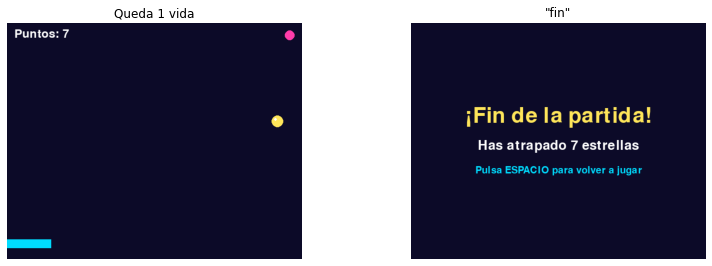

In [13]:
reiniciar()
puntos = 7
cesta.left = 0
while estado == "jugando":
    estrella_x = WIDTH - 50                  # siempre lejos de la cesta
    vidas_antes = vidas
    update()
    if vidas != vidas_antes:
        print("Se ha escapado una estrella → vidas =", vidas, "· estado =", estado)
        if vidas == 1:
            estrella_x, estrella_y = WIDTH - 50, 200
            draw(); captura_una_vida = screen.imagen()

draw(); captura_fin = screen.imagen()
on_key_down(keys.SPACE)
print("Tras pulsar ESPACIO → estado =", estado, "· puntos =", puntos, "· vidas =", vidas)
mostrar(captura_una_vida, captura_fin, titulos=["Queda 1 vida", '"fin"'])

---
## 🎬 Partida completa simulada
Un "robot" pulsa las flechas para acercar la cesta a la estrella, pero a veces se despista. Ejecutamos `update()` y `draw()` como haría Pygame Zero y guardamos los fotogramas en un GIF. *(Tarda unos segundos).*

Estrellas atrapadas: 22 · estado: fin · 509 fotogramas


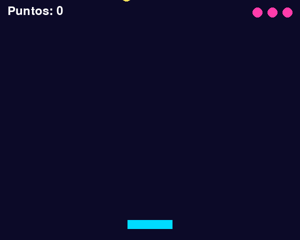

In [14]:
def robot():
    """Pulsa ← o → para seguir a la estrella, con algún despiste."""
    keyboard.left = keyboard.right = False
    if random.random() < 0.45:
        return
    if estrella_x < cesta.centerx - 10:
        keyboard.left = True
    elif estrella_x > cesta.centerx + 10:
        keyboard.right = True


random.seed(4)
reiniciar()
fotogramas = []
for n in range(6000):
    robot()
    update()
    if n % 4 == 0:
        draw()
        fotogramas.append(screen.imagen().resize((300, 240)))
    if estado == "fin":
        break
keyboard.left = keyboard.right = False
draw()
for _ in range(20):
    fotogramas.append(screen.imagen().resize((300, 240)))

buffer = io.BytesIO()
fotogramas[0].save(buffer, format="GIF", save_all=True, append_images=fotogramas[1:],
                   duration=65, loop=0, optimize=True)
print(f"Estrellas atrapadas: {puntos} · estado: {estado} · {len(fotogramas)} fotogramas")
display(IPyImage(data=buffer.getvalue(), format="gif"))

---
## 📦 El programa completo: `estrella.py`
Esta celda guarda la solución completa (con `import pgzrun` y `pgzrun.go()`, ya con Pygame Zero de verdad). Para jugar en tu ordenador:
```
pip install pgzero
python estrella.py
```

In [15]:
%%writefile estrella.py
# Solución de referencia - Actividad "Atrapa la estrella" (1º DAW - Programación)
import random
import pgzrun

WIDTH = 600
HEIGHT = 480
TITLE = "Atrapa la estrella - 1º DAW"

# Constantes del juego
COLOR_FONDO = (12, 10, 40)
COLOR_CESTA = (0, 220, 255)
COLOR_ESTRELLA = (255, 230, 90)
COLOR_VIDA = (255, 60, 170)
COLOR_TEXTO = (255, 255, 255)

CESTA_ANCHO = 90
CESTA_ALTO = 18
CESTA_VELOCIDAD = 8
RADIO = 12
VELOCIDAD_INICIAL = 3
AUMENTO_VELOCIDAD = 0.3
VIDAS_INICIALES = 3

# Estado del juego (variables globales)
cesta = Rect(WIDTH // 2 - CESTA_ANCHO // 2, HEIGHT - 40, CESTA_ANCHO, CESTA_ALTO)
estrella_x = WIDTH / 2
estrella_y = -RADIO
velocidad = VELOCIDAD_INICIAL
puntos = 0
vidas = VIDAS_INICIALES
estado = "jugando"       # "jugando" o "fin"


def nueva_estrella():
    """Coloca la estrella arriba del todo, en una x aleatoria."""
    global estrella_x, estrella_y
    estrella_x = random.randint(RADIO, WIDTH - RADIO)
    estrella_y = -RADIO


def reiniciar():
    global velocidad, puntos, vidas, estado
    velocidad = VELOCIDAD_INICIAL
    puntos = 0
    vidas = VIDAS_INICIALES
    estado = "jugando"
    cesta.centerx = WIDTH // 2
    nueva_estrella()


def mover_cesta():
    if keyboard.left:
        cesta.x -= CESTA_VELOCIDAD
    if keyboard.right:
        cesta.x += CESTA_VELOCIDAD

    if cesta.left < 0:
        cesta.left = 0
    if cesta.right > WIDTH:
        cesta.right = WIDTH


def mover_estrella():
    global estrella_y, puntos, vidas, velocidad, estado
    estrella_y += velocidad

    caja = Rect(estrella_x - RADIO, estrella_y - RADIO, RADIO * 2, RADIO * 2)
    if caja.colliderect(cesta):
        # ¡Atrapada!
        puntos += 1
        velocidad += AUMENTO_VELOCIDAD
        nueva_estrella()
    elif estrella_y - RADIO > HEIGHT:
        # Se ha escapado por abajo
        vidas -= 1
        nueva_estrella()
        if vidas == 0:
            estado = "fin"


def update():
    if estado == "jugando":
        mover_cesta()
        mover_estrella()


def on_key_down(key):
    if estado == "fin" and key == keys.SPACE:
        reiniciar()


def dibujar_marcador():
    screen.draw.text("Puntos: " + str(puntos), topleft=(15, 10),
                     fontsize=36, color=COLOR_TEXTO)
    for i in range(vidas):
        screen.draw.filled_circle((WIDTH - 25 - i * 30, 25), 10, COLOR_VIDA)


def draw():
    screen.fill(COLOR_FONDO)
    if estado == "jugando":
        screen.draw.filled_circle((estrella_x, estrella_y), RADIO, COLOR_ESTRELLA)
        screen.draw.filled_circle((estrella_x - 4, estrella_y - 4), 3, COLOR_TEXTO)
        screen.draw.filled_rect(cesta, COLOR_CESTA)
        dibujar_marcador()
    else:
        screen.draw.text("¡Fin de la partida!", center=(WIDTH / 2, HEIGHT / 2 - 50),
                         fontsize=64, color=COLOR_ESTRELLA)
        screen.draw.text("Has atrapado " + str(puntos) + " estrellas",
                         center=(WIDTH / 2, HEIGHT / 2 + 10),
                         fontsize=40, color=COLOR_TEXTO)
        screen.draw.text("Pulsa ESPACIO para volver a jugar",
                         center=(WIDTH / 2, HEIGHT / 2 + 60),
                         fontsize=30, color=COLOR_CESTA)


pgzrun.go()

Writing estrella.py


In [16]:
# Descarga estrella.py a tu ordenador (solo funciona dentro de Google Colab)
try:
    from google.colab import files
    files.download("estrella.py")
except ImportError:
    print("No estás en Colab: el fichero estrella.py está en la carpeta actual.")

No estás en Colab: el fichero estrella.py está en la carpeta actual.


---
## 🧾 Resumen

| Fase | Qué hace | Conceptos |
|---|---|---|
| 1 | Marcador y vidas | constantes, variables, `str()`, `for` + `range()` |
| 2 | Mover la cesta | `keyboard`, `if`, atributos de un objeto (`cesta.left`) |
| 3 | La estrella cae | `+=`, `global`, funciones, `random.randint()` |
| 4 | Atrapar | `colliderect()`, `if / elif` |
| 5 | Vidas y fin | variable de estado, `on_key_down()`, función `reiniciar()` |

## 🐞 Errores frecuentes

| Síntoma | Causa probable | Solución |
|---|---|---|
| `UnboundLocalError` | Falta `global` en la función | Añade `global estrella_y, ...` |
| `TypeError: can only concatenate str` | `"Puntos: " + puntos` | Usa `str(puntos)` |
| La estrella sale cortada por un lado | `randint(0, WIDTH)` | Usa `randint(RADIO, WIDTH - RADIO)` |
| La estrella cae una sola vez | No se llama a `nueva_estrella()` al salir | Comprueba `estrella_y - RADIO > HEIGHT` |
| Tras el fin, la cesta se sigue moviendo | `update()` no mira el estado | `if estado == "jugando":` |

## ✅ Autoevaluación

<details><summary><b>1. ¿Qué pasa si <code>AUMENTO_VELOCIDAD = 0</code>?</b></summary>
Todas las estrellas caen a la misma velocidad y el juego nunca se vuelve más difícil.
</details>

<details><summary><b>2. ¿Por qué <code>reiniciar()</code> llama a <code>nueva_estrella()</code>?</b></summary>
Para que la primera estrella de la nueva partida empiece arriba, y no en el sitio donde estaba al terminar la anterior.
</details>

<details><summary><b>3. ¿Cómo harías que la partida empezara con 5 vidas?</b></summary>
Cambiando una sola línea: <code>VIDAS_INICIALES = 5</code>.
</details>

<details><summary><b>4. ¿Por qué el texto final se escribe solo cuando <code>estado != "jugando"</code>?</b></summary>
Porque <code>draw()</code> elige qué pantalla dibujar según el estado: así el juego y la pantalla final nunca se mezclan.
</details>

➡️ **Siguiente paso:** la práctica *Boing!*, tu propio Pong.